# Target Words: Exploration

Explores the full target word set and how it narrows down through each stage of the project.

## Dataset

The project uses a curated list of 750 German nouns, verbs, and adjectives from Charbonnier & Wartena (2019), selected for their polysemy and frequency in the DWDS kern corpus. Each word has a concreteness rating (`num_senses` column in the Excel file — a Brysbaert-style 1–7 scale averaged across annotators). Note: the Excel column names are misleading — `num_senses` is actually the concreteness score, and `conc_score` is actually the GermaNet sense count. Additionally, 119 of the 750 `num_senses` values are corrupted by Excel's date auto-conversion and are excluded from the concreteness plot. Polysemy is derived from GermaNet instead of the Excel file.

The set narrows at each project stage: 750 target words → 700 with GermaNet senses → 116 selected for the diachronic pilot → 90 with sufficient DWDS data.

**Files used:**
- `data/raw/target_words/target_words_clean.xlsx` — 750 words with concreteness score
- `data/processed/germanet/senses_full.jsonl` — 2,022 senses for 700 words (POS, semantic class, paraphrase/example coverage, LLM definitions and examples)
- `data/raw/target_words/pilot_words_diachronic.txt` — the 116 pilot words
- `data/processed/dwds/pilot_contexts.jsonl` — DWDS contexts for the pilot set

## 1. Setup & Load Data

In [5]:
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11

ROOT = Path('../..')

In [ ]:
# Full target word set
words_df = pd.read_excel(ROOT / 'data/raw/target_words/target_words_clean.xlsx')
words_df = words_df.rename(columns={'Concreteness': 'lemma'})
# Note: num_senses is corrupted by Excel date auto-conversion — not used

# GermaNet senses (enhanced: includes LLM-generated definitions and examples)
senses_df = pd.read_json(ROOT / 'data/processed/germanet/senses_full.jsonl', lines=True)

# Pilot words
pilot_words = (ROOT / 'data/raw/target_words/pilot_words_diachronic.txt').read_text().splitlines()
pilot_words = [w.strip() for w in pilot_words if w.strip()]

In [7]:
words_df

,lemma,devel,num_senses,conc_score
0,Abend,Ja,4.97,2.0
1,Adler,Ja,6.14,1.0
2,Adresse,Ja,4.99,4.0
3,Affe,Ja,6.33,2.0
4,Alarm,Ja,4.82,1.0
...,...,...,...,...
745,Zunge,Ja,6.52,4.0
746,Zwerg,Ja,2025-05-06 00:00:00,2.0
747,Zwiebel,Ja,6.62,3.0
748,Zwilling,Ja,5.98,2.0


In [8]:
senses_df.iloc[0].text_for_embedding

'ART: ein monatlich erscheinendes Kunstmagazin. ART ist eine Art von Kunstblatt. ART ist ein Begriff aus Artefakt'

In [ ]:
# Full target word set
words_df = pd.read_excel(ROOT / 'data/raw/target_words/target_words_clean.xlsx')
words_df = words_df.rename(columns={'Concreteness': 'lemma'})
# Note: num_senses is corrupted by Excel date auto-conversion — not used

# GermaNet senses (enhanced: includes LLM-generated definitions and examples)
senses_df = pd.read_json(ROOT / 'data/processed/germanet/senses_full.jsonl', lines=True)

# Pilot words
pilot_words = (ROOT / 'data/raw/target_words/pilot_words_diachronic.txt').read_text().splitlines()
pilot_words = [w.strip() for w in pilot_words if w.strip()]

# DWDS contexts
contexts = []
with open(ROOT / 'data/processed/dwds/pilot_contexts.jsonl', encoding='utf-8') as f:
    for line in f:
        r = json.loads(line)
        contexts.append({'lemma': r['lemma'], 'decade': r['decade'], 'genre': r['genre']})
contexts_df = pd.DataFrame(contexts)

# Words with both GermaNet senses and DWDS data
dwds_words = sorted(contexts_df['lemma'].unique())
dwds_words_with_senses = [w for w in dwds_words if w in senses_df['lemma'].values]

print(f'Full target set:        {len(words_df)} words')
print(f'With GermaNet senses:   {senses_df["lemma"].nunique()} words ({senses_df.shape[0]} senses)')
print(f'Pilot set:              {len(pilot_words)} words')
print(f'With DWDS data:         {len(dwds_words_with_senses)} words (GermaNet senses + DWDS contexts)')

## 2. The Selection Funnel

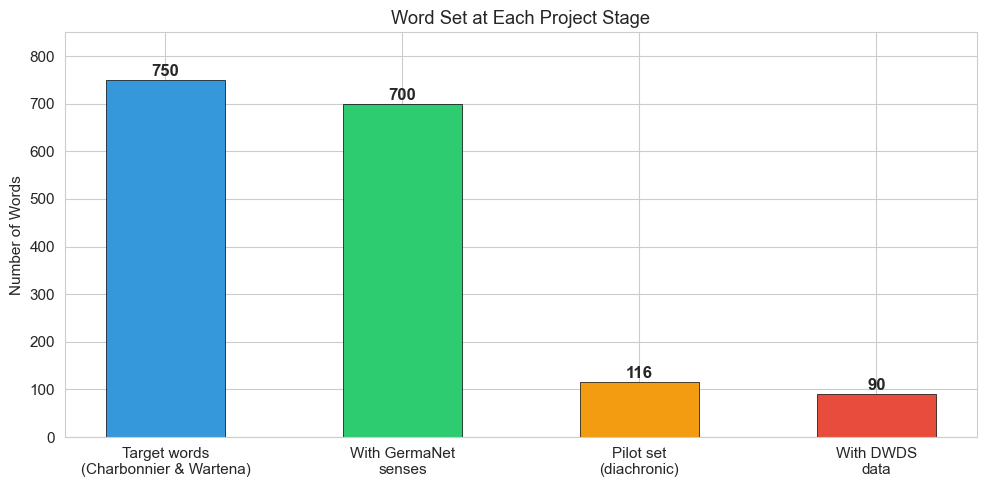

In [10]:
stages = ['Target words\n(Charbonnier & Wartena)', 'With GermaNet\nsenses', 'Pilot set\n(diachronic)', 'With DWDS\ndata']
counts = [750, senses_df['lemma'].nunique(), len(pilot_words), len(dwds_words_with_senses)]
colors = ['#3498db', '#2ecc71', '#f39c12', '#e74c3c']

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(stages, counts, color=colors, edgecolor='black', linewidth=0.5, width=0.5)
for bar, v in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 8,
            str(v), ha='center', fontsize=12, fontweight='bold')
ax.set_ylabel('Number of Words')
ax.set_title('Word Set at Each Project Stage')
ax.set_ylim(0, 850)
plt.tight_layout()
plt.show()

The set loses 50 words between the full list and GermaNet (words not found in the lexicon), then narrows sharply to 116 for the pilot (stratified sample by polysemy and POS). A further 26 pilot words have no GermaNet senses and are excluded from WSD predictions, leaving 90 words with both sense inventories and DWDS contexts.

## 3. Full Target Word Set (750 words)

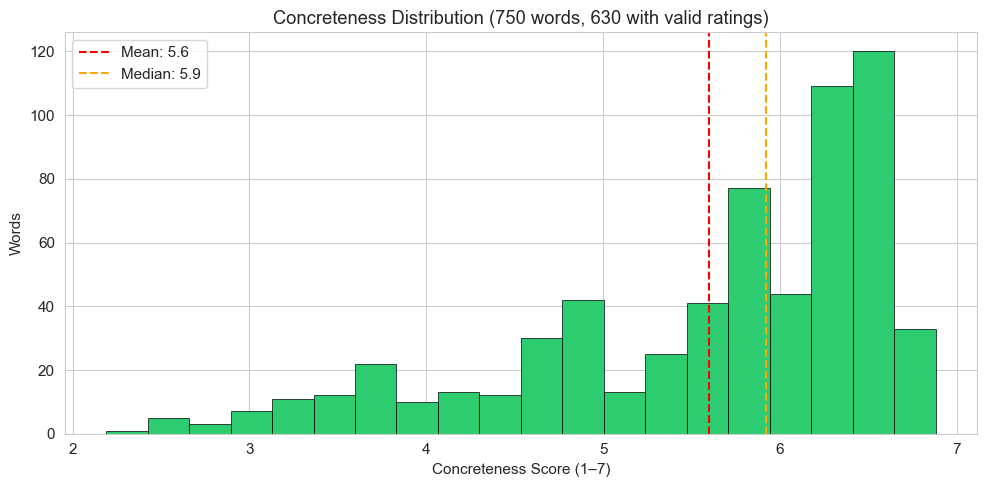

Concreteness — mean: 5.60, range: 2.19–6.88, n=630


In [11]:
# Concreteness distribution (words_df)
# num_senses is the actual concreteness rating (Brysbaert 1–7 scale); 119 rows are
# corrupted by Excel date auto-conversion and are dropped here.
conc = pd.to_numeric(words_df['num_senses'], errors='coerce').dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(conc, bins=20, color='#2ecc71', edgecolor='black', linewidth=0.5)
ax.axvline(conc.mean(), color='red', linestyle='--', label=f'Mean: {conc.mean():.1f}')
ax.axvline(conc.median(), color='orange', linestyle='--', label=f'Median: {conc.median():.1f}')
ax.set_xlabel('Concreteness Score (1–7)')
ax.set_ylabel('Words')
ax.set_title('Concreteness Distribution (750 words, 630 with valid ratings)')
ax.legend()
plt.tight_layout()
plt.show()

print(f'Concreteness — mean: {conc.mean():.2f}, range: {conc.min():.2f}–{conc.max():.2f}, n={len(conc)}')

Polysemy is right-skewed: most words have a modest number of senses but a long tail of highly polysemous words pulls the mean up. Concreteness is spread across the scale, reflecting the deliberate stratification in the original word list.

## 4. GermaNet Coverage (700 words, 2,022 senses)

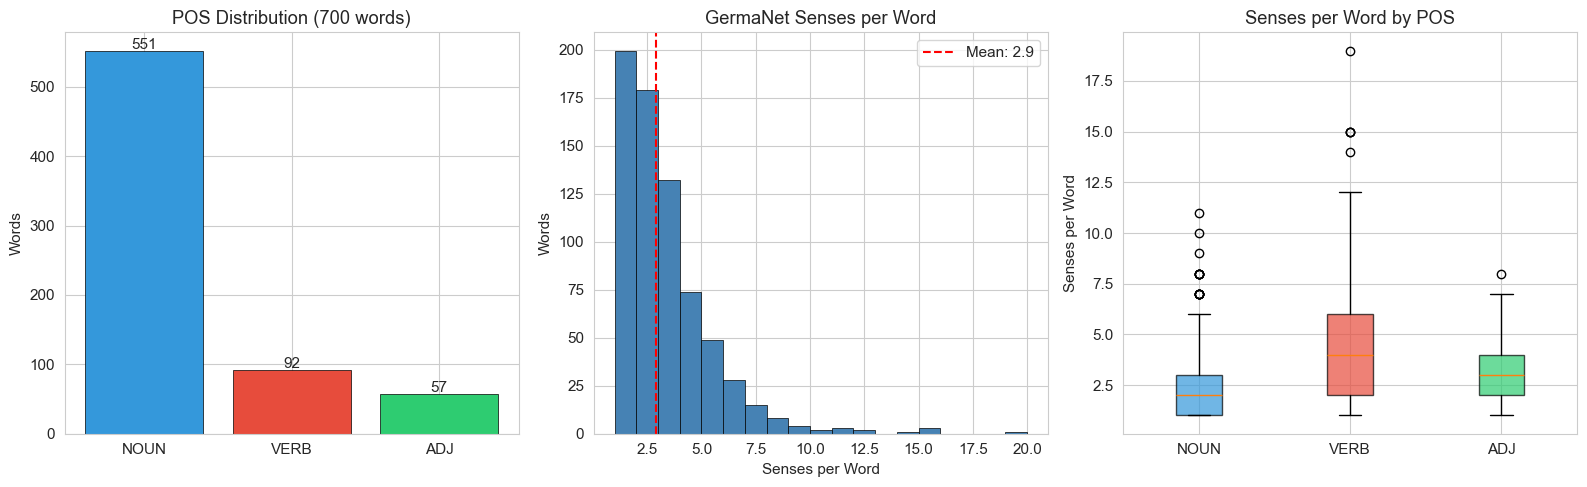

Mean senses per word by POS:
  NOUN: 2.52 (max: 11)
  VERB: 4.87 (max: 19)
  ADJ: 3.25 (max: 8)


In [12]:
# POS and senses per word
senses_per_word = senses_df.groupby('lemma').size()
pos_per_word = senses_df.groupby('lemma')['pos'].first()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# POS distribution
pos_counts = pos_per_word.value_counts()
axes[0].bar(pos_counts.index, pos_counts.values,
            color=['#3498db', '#e74c3c', '#2ecc71'], edgecolor='black', linewidth=0.5)
for i, v in enumerate(pos_counts.values):
    axes[0].text(i, v + 3, str(v), ha='center', fontsize=11)
axes[0].set_title('POS Distribution (700 words)')
axes[0].set_ylabel('Words')

# Senses per word overall
axes[1].hist(senses_per_word.values, bins=range(1, senses_per_word.max() + 2),
             color='steelblue', edgecolor='black', linewidth=0.5)
axes[1].axvline(senses_per_word.mean(), color='red', linestyle='--',
                label=f'Mean: {senses_per_word.mean():.1f}')
axes[1].set_xlabel('Senses per Word')
axes[1].set_ylabel('Words')
axes[1].set_title('GermaNet Senses per Word')
axes[1].legend()

# Senses per word by POS (boxplot)
pos_order = ['NOUN', 'VERB', 'ADJ']
data_by_pos = [senses_per_word[pos_per_word[pos_per_word == p].index].values for p in pos_order]
bp = axes[2].boxplot(data_by_pos, tick_labels=pos_order, patch_artist=True)
for patch, color in zip(bp['boxes'], ['#3498db', '#e74c3c', '#2ecc71']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[2].set_ylabel('Senses per Word')
axes[2].set_title('Senses per Word by POS')

plt.tight_layout()
plt.show()

print('Mean senses per word by POS:')
for p in pos_order:
    vals = senses_per_word[pos_per_word[pos_per_word == p].index]
    print(f'  {p}: {vals.mean():.2f} (max: {vals.max()})')

Nouns dominate the word list, reflecting their frequency in the original Charbonnier & Wartena selection. Verbs have the highest average polysemy in GermaNet, which makes them both the most interesting and the hardest targets for WSD.

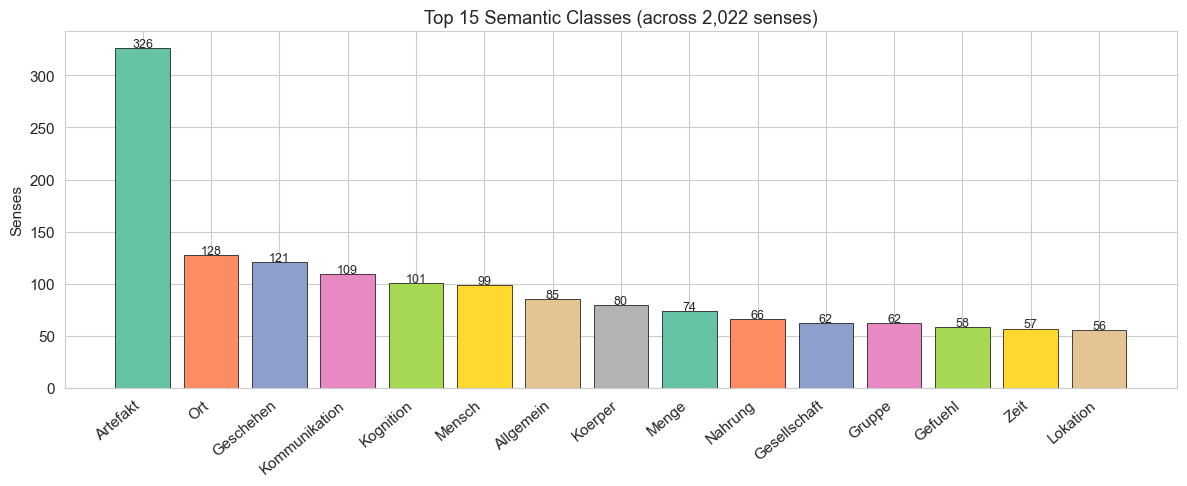

In [13]:
# Top semantic classes
class_counts = senses_df['class'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(range(len(class_counts)), class_counts.values,
              color=sns.color_palette('Set2', len(class_counts)),
              edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1,
            str(v), ha='center', fontsize=9)
ax.set_xticks(range(len(class_counts)))
ax.set_xticklabels(class_counts.index, rotation=40, ha='right')
ax.set_ylabel('Senses')
ax.set_title('Top 15 Semantic Classes (across 2,022 senses)')
plt.tight_layout()
plt.show()

,count,pct
coverage,,
Has paraphrase,480,23.7
Has examples,465,23.0
Text from examples,465,23.0
Text from relations,1557,77.0


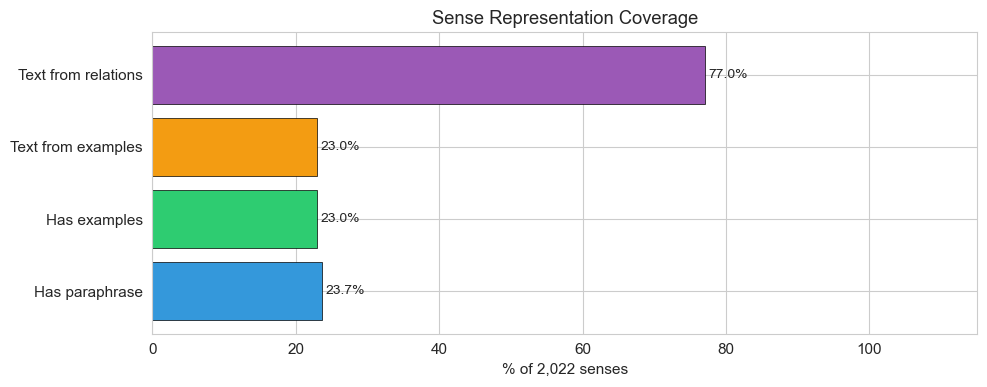

In [14]:
# Paraphrase and example coverage
has_paraphrase = senses_df['paraphrase'].notna().sum()
has_examples = senses_df['has_examples'].sum()
n_senses = len(senses_df)

coverage = pd.DataFrame({
    'coverage': ['Has paraphrase', 'Has examples', 'Text from examples', 'Text from relations'],
    'count': [
        has_paraphrase,
        has_examples,
        (senses_df['text_source'] == 'example').sum(),
        (senses_df['text_source'] == 'direct_relations').sum(),
    ]
})
coverage['pct'] = (coverage['count'] / n_senses * 100).round(1)
coverage = coverage.set_index('coverage')

display(coverage)

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(coverage.index, coverage['pct'],
               color=['#3498db', '#2ecc71', '#f39c12', '#9b59b6'],
               edgecolor='black', linewidth=0.5)
for bar, v in zip(bars, coverage['pct']):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f'{v}%', va='center', fontsize=10)
ax.set_xlabel('% of 2,022 senses')
ax.set_title('Sense Representation Coverage')
ax.set_xlim(0, 115)
plt.tight_layout()
plt.show()

Paraphrase coverage is limited in GermaNet — the majority of senses rely on relational text (hypernym chains) rather than a direct definition. Example sentences are available for roughly a quarter of senses and are used as the primary text source when present, since they give richer disambiguation signal than relation-derived text.

## 5. The Pilot Set (116 words)

In [15]:
# Pilot words split by GermaNet availability
pilot_with_senses = [w for w in pilot_words if w in senses_df['lemma'].values]
pilot_no_senses = [w for w in pilot_words if w not in senses_df['lemma'].values]

print(f'Pilot words total:          {len(pilot_words)}')
print(f'With GermaNet senses:       {len(pilot_with_senses)}')
print(f'Without GermaNet senses:    {len(pilot_no_senses)}')
print(f'\nWords without GermaNet senses:')
print(', '.join(sorted(pilot_no_senses)))

Pilot words total:          116
With GermaNet senses:       90
Without GermaNet senses:    26

Words without GermaNet senses:
Bauer, Becher, Bild, Fall, Farbe, Figur, Gang, Husten, Knoten, Paket, Seite, Stück, Wurzel, Zug, brennen, fahren, folgen, halten, heißen, lassen, legen, liegen, riechen, schließen, sehen, stehen


The 26 words without GermaNet senses are mostly high-frequency verbs (*fahren*, *sehen*, *halten*, *stehen*, *gehen*, etc.) and a few nouns. These words are present in the raw GermaNet data but were lost during processing — likely because their lemma form didn't match the GermaNet entry. They are deferred to Phase 4.

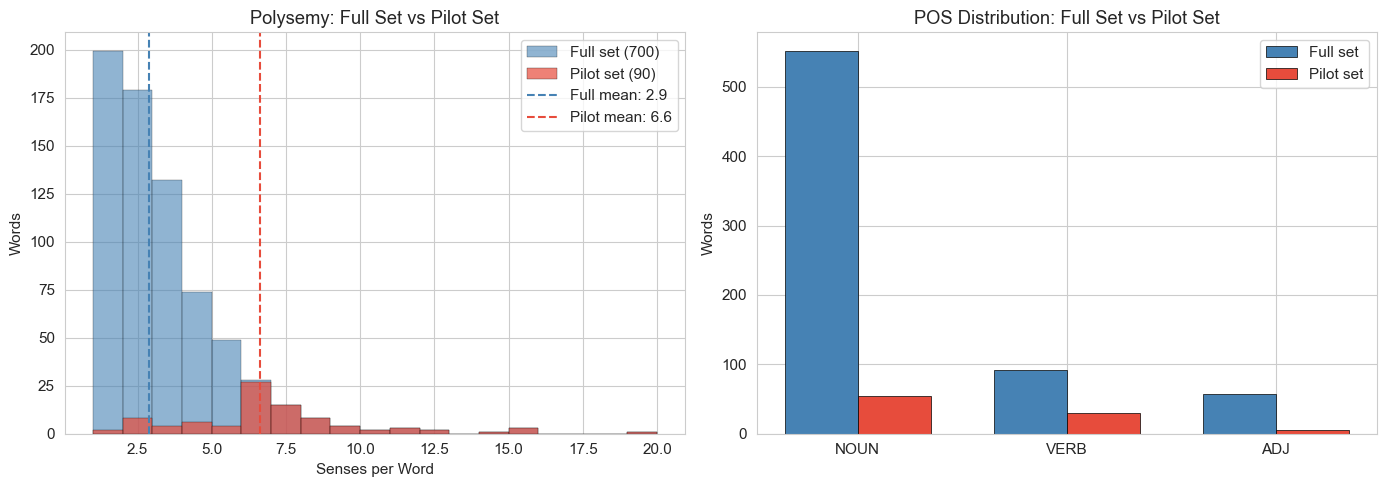

In [16]:
# Polysemy: pilot set vs full set
pilot_senses = senses_df[senses_df['lemma'].isin(pilot_with_senses)]
pilot_senses_per_word = pilot_senses.groupby('lemma').size()
full_senses_per_word = senses_df.groupby('lemma').size()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram comparison
bins = range(1, max(full_senses_per_word.max(), pilot_senses_per_word.max()) + 2)
axes[0].hist(full_senses_per_word.values, bins=bins, alpha=0.6, label='Full set (700)',
             color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].hist(pilot_senses_per_word.values, bins=bins, alpha=0.7, label='Pilot set (90)',
             color='#e74c3c', edgecolor='black', linewidth=0.3)
axes[0].axvline(full_senses_per_word.mean(), color='steelblue', linestyle='--',
                label=f'Full mean: {full_senses_per_word.mean():.1f}')
axes[0].axvline(pilot_senses_per_word.mean(), color='#e74c3c', linestyle='--',
                label=f'Pilot mean: {pilot_senses_per_word.mean():.1f}')
axes[0].set_xlabel('Senses per Word')
axes[0].set_ylabel('Words')
axes[0].set_title('Polysemy: Full Set vs Pilot Set')
axes[0].legend()

# POS distribution of pilot set
pilot_pos = pilot_senses.groupby('lemma')['pos'].first().value_counts()
full_pos = senses_df.groupby('lemma')['pos'].first().value_counts()
pos_order = ['NOUN', 'VERB', 'ADJ']
x = np.arange(len(pos_order))
w = 0.35
axes[1].bar(x - w/2, [full_pos.get(p, 0) for p in pos_order], w,
            label='Full set', color='steelblue', edgecolor='black', linewidth=0.5)
axes[1].bar(x + w/2, [pilot_pos.get(p, 0) for p in pos_order], w,
            label='Pilot set', color='#e74c3c', edgecolor='black', linewidth=0.5)
axes[1].set_xticks(x)
axes[1].set_xticklabels(pos_order)
axes[1].set_ylabel('Words')
axes[1].set_title('POS Distribution: Full Set vs Pilot Set')
axes[1].legend()

plt.tight_layout()
plt.show()

The pilot set was deliberately stratified by polysemy, so its mean senses-per-word is higher than the full set — it oversamples polysemous words, which are more interesting for diachronic analysis. The POS distribution broadly mirrors the full set, with nouns dominant.

## 6. DWDS Coverage (90 words)

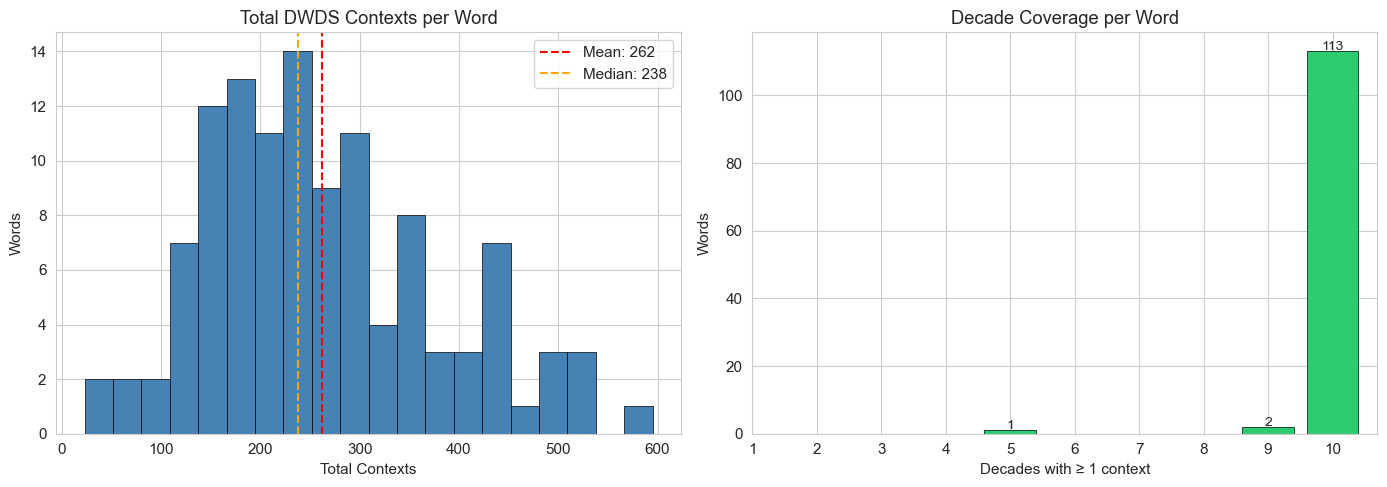

Words with all 10 decades covered: 113
Words missing ≥ 1 decade:          3

Lowest coverage words:
lemma
schneiden    125
springen     123
schwarz      117
schlagen     111
Frosch       106
riechen       99
Zwiebel       68
heißen        60
groß          47
Bass          23


In [17]:
word_contexts = contexts_df.groupby('lemma').size().sort_values(ascending=False)
word_decades = contexts_df.groupby('lemma')['decade'].nunique()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(word_contexts.values, bins=20, color='steelblue', edgecolor='black', linewidth=0.5)
axes[0].axvline(word_contexts.mean(), color='red', linestyle='--',
                label=f'Mean: {word_contexts.mean():.0f}')
axes[0].axvline(word_contexts.median(), color='orange', linestyle='--',
                label=f'Median: {word_contexts.median():.0f}')
axes[0].set_xlabel('Total Contexts')
axes[0].set_ylabel('Words')
axes[0].set_title('Total DWDS Contexts per Word')
axes[0].legend()

decade_dist = word_decades.value_counts().sort_index()
axes[1].bar(decade_dist.index, decade_dist.values,
            color='#2ecc71', edgecolor='black', linewidth=0.5)
for i, v in zip(decade_dist.index, decade_dist.values):
    axes[1].text(i, v + 0.3, str(v), ha='center', fontsize=10)
axes[1].set_xlabel('Decades with ≥ 1 context')
axes[1].set_ylabel('Words')
axes[1].set_title('Decade Coverage per Word')
axes[1].set_xticks(range(1, 11))

plt.tight_layout()
plt.show()

print(f'Words with all 10 decades covered: {(word_decades == 10).sum()}')
print(f'Words missing ≥ 1 decade:          {(word_decades < 10).sum()}')
print(f'\nLowest coverage words:')
print(word_contexts.tail(10).to_string())

Most words are well-covered across all 10 decades. Words missing one or more decades will have gaps in their sense trajectories — these gaps are already handled by the minimum-context filter in the change metrics, but they reduce the number of valid decade transitions available for analysis.